In [11]:
#LECTURE 7 (DATA MANIPULATION)
# Method-2
import pandas as pd

file_path = '/content/SkyBridge_Airline_Data (1).xlsx'
sheet_name = "Unclean_Data"

# Read the excel file to create the 'raw' DataFrame
raw = pd.read_excel(file_path, sheet_name=sheet_name)

# The 9 numeric columns we will study
num_cols = ["Passengers", "Ticket_Price", "Delay_Minutes", "Flight_Duration_Min", "Fuel_Cost",
            "Ancillary_Revenue", "Baggage_Complaints", "Customer_Rating", "Crew_Overtime_Hours"]

print("Rows and Columns:", raw.shape)
raw.head()

Rows and Columns: (120, 12)


,Date,Flight_ID,Route,Passengers,Ticket_Price,Delay_Minutes,Flight_Duration_Min,Fuel_Cost,Ancillary_Revenue,Baggage_Complaints,Customer_Rating,Crew_Overtime_Hours
0,2026-01-01,SB-001,Delhi-Mumbai,143.0,5650.0,26.0,133.0,429.0,60600.0,2.0,3.9,NaN
1,2026-01-02,SB-002,Delhi-Bengaluru,158.0,7200.0,18.0,163.0,528.0,67600.0,3.0,4.1,6.3
2,2026-01-03,SB-003,Delhi-Bengaluru,178.0,6200.0,6.0,169.0,585.0,71700.0,3.0,4.4,5.3
3,2026-01-04,SB-004,Delhi-Mumbai,145.0,5800.0,9.0,131.0,433.0,61400.0,4.0,4.1,4.0
4,2026-01-05,SB-005,Delhi-Mumbai,159.0,5450.0,18.0,130.0,428.0,70000.0,2.0,4.0,8.7


Blank cells: 58
Blank %: 4.0 %
Rows with at least one blank: 48 out of 120


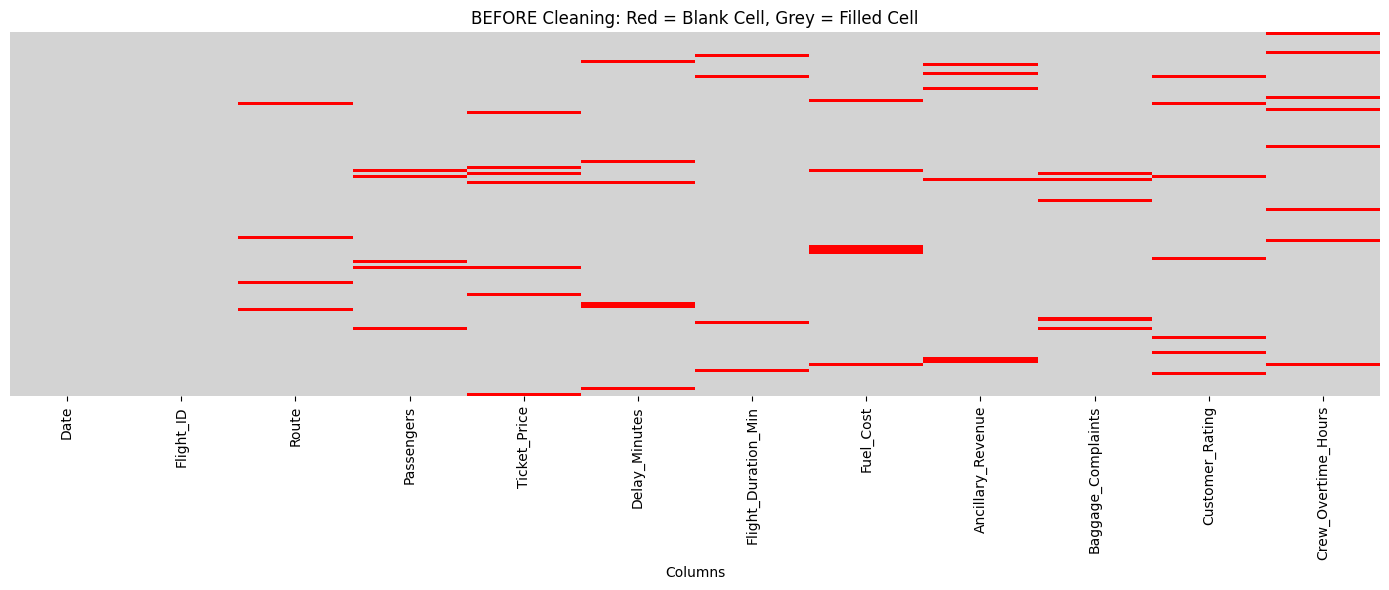

In [12]:
# Count all blank cells
total_blank = raw.isnull().sum().sum()

print("Blank cells:", total_blank)

# Calculate percentage of blank cells
print(
    "Blank %:",
    round((total_blank / raw.size) * 100, 1),
    "%"
)

# Count rows with at least one blank
rows_with_blank = raw.isnull().any(axis=1).sum()

print(
    "Rows with at least one blank:",
    rows_with_blank,
    "out of",
    len(raw)
)

# BEFORE heatmap: red = blank cell, grey = filled cell
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(14, 6))
sns.heatmap(
    raw.isnull(),
    cbar=False,
    yticklabels=False,
    cmap=["lightgrey", "red"]
)

plt.title("BEFORE Cleaning: Red = Blank Cell, Grey = Filled Cell")
plt.xlabel("Columns")
plt.tight_layout()
plt.show()

In [13]:
#Descriptive statistics: spot values that look wrong

raw[num_cols].describe().round(1)

,Passengers,Ticket_Price,Delay_Minutes,Flight_Duration_Min,Fuel_Cost,Ancillary_Revenue,Baggage_Complaints,Customer_Rating,Crew_Overtime_Hours
count,115.0,113.0,114.0,116.0,114.0,114.0,115.0,113.0,112.0
mean,155.0,6374.3,19.4,157.2,511.2,59615.8,3.1,4.2,6.5
std,13.6,4836.7,35.9,30.0,78.0,11182.3,2.4,0.6,2.8
min,120.0,4800.0,-45.0,122.0,398.0,37900.0,0.0,3.5,2.8
25%,147.0,5550.0,9.0,132.0,433.0,54425.0,2.0,4.0,5.2
50%,155.0,5900.0,16.0,165.0,530.0,58800.0,3.0,4.1,6.1
75%,163.0,6300.0,23.8,170.0,563.8,64225.0,4.0,4.3,7.3
max,215.0,57000.0,380.0,410.0,980.0,148000.0,19.0,9.4,31.5


In [14]:
# A big gap between mean and median is a warning sign

gap = pd.DataFrame({
    "Mean": raw[num_cols].mean(),
    "Median": raw[num_cols].median(),
})

gap["Gap %"] = ((gap["Mean"] - gap["Median"]) / gap["Median"] * 100).round(1)

gap.round(1)

,Mean,Median,Gap %
Passengers,155.0,155.0,-0.0
Ticket_Price,6374.3,5900.0,8.0
Delay_Minutes,19.4,16.0,21.2
Flight_Duration_Min,157.2,165.0,-4.7
Fuel_Cost,511.2,530.0,-3.5
Ancillary_Revenue,59615.8,58800.0,1.4
Baggage_Complaints,3.1,3.0,3.5
Customer_Rating,4.2,4.1,1.8
Crew_Overtime_Hours,6.5,6.1,6.2


# Setting rules for our variable


In [15]:
rules = {
    "Passengers": (0, 180),              # aircraft has 180 seats
    "Ticket_Price": (1000, 20000),       # domestic low-cost fare in INR
    "Delay_Minutes": (0, 600),           # a delay cannot be negative
    "Flight_Duration_Min": (60, 240),    # domestic sector
    "Customer_Rating": (1, 5),           # rating scale 1 to 5
}

for col, (low, high) in rules.items():
    bad = raw[(raw[col] < low) | (raw[col] > high)]
    print(col, "-> impossible values:", len(bad))
    if len(bad) > 0:
        print(bad[["Date", "Flight_ID", col]].to_string(index=False))
    print()

Passengers -> impossible values: 1
      Date Flight_ID  Passengers
2026-02-07    SB-038       215.0

Ticket_Price -> impossible values: 1
      Date Flight_ID  Ticket_Price
2026-01-15    SB-015       57000.0

Delay_Minutes -> impossible values: 1
      Date Flight_ID  Delay_Minutes
2026-01-23    SB-023          -45.0

Flight_Duration_Min -> impossible values: 1
      Date Flight_ID  Flight_Duration_Min
2026-04-02    SB-092                410.0

Customer_Rating -> impossible values: 1
      Date Flight_ID  Customer_Rating
2026-03-18    SB-077              9.4



STEP 2 TIME SERIES PLOT

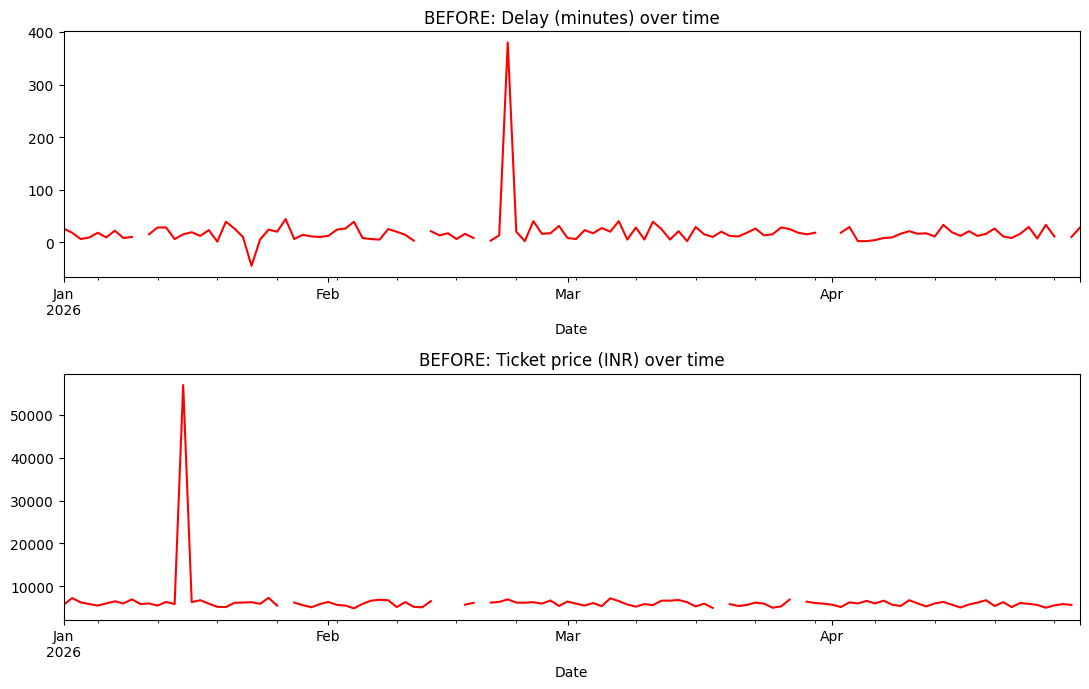

In [16]:
# Time series view (one flight per day)
# Gaps in the line are blank cells. Spikes and dips are unusual values.

ts_raw = raw.set_index("Date")

fig, axes = plt.subplots(2, 1, figsize=(11, 7))

ts_raw["Delay_Minutes"].plot(
    ax=axes[0],
    color="red",
    title="BEFORE: Delay (minutes) over time"
)

ts_raw["Ticket_Price"].plot(
    ax=axes[1],
    color="red",
    title="BEFORE: Ticket price (INR) over time"
)

plt.tight_layout()
plt.show()

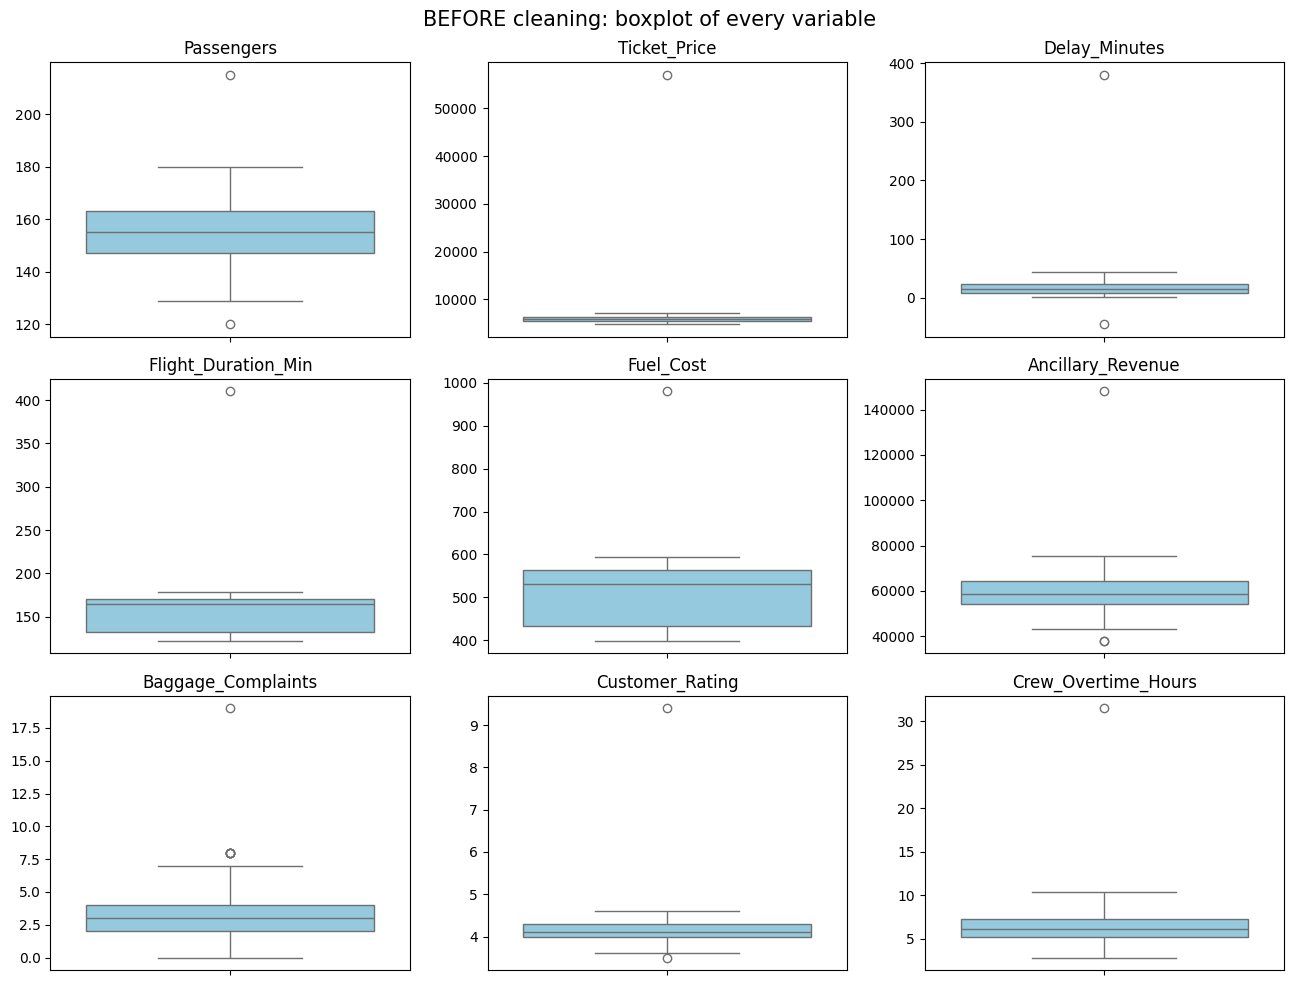

In [17]:
import seaborn as sns
import matplotlib.pyplot as plt

def show_boxplots(data, title):
    fig, axes = plt.subplots(3, 3, figsize=(13, 10))
    axes = axes.flatten()

    for i, col in enumerate(num_cols):
        sns.boxplot(y=data[col], ax=axes[i], color="skyblue")
        axes[i].set_title(col)
        axes[i].set_ylabel("")

    fig.suptitle(title, fontsize=15)
    plt.tight_layout()
    plt.show()

show_boxplots(raw, "BEFORE cleaning: boxplot of every variable")

STEP 3- RETAINING, MOVING AND CAPPING THE DATA


In [18]:
raw[raw["Delay_Minutes"] > 100]

,Date,Flight_ID,Route,Passengers,Ticket_Price,Delay_Minutes,Flight_Duration_Min,Fuel_Cost,Ancillary_Revenue,Baggage_Complaints,Customer_Rating,Crew_Overtime_Hours
52,2026-02-22,SB-053,Delhi-Bengaluru,147.0,6900.0,380.0,173.0,980.0,62500.0,19.0,4.2,31.5


STEP 4 REMOVE IMPOSSIBLE VALUE

In [20]:
import numpy as np

# Create a copy
df = raw.copy()

# Find ratings below 1 or above 5
bad_values = (df["Customer_Rating"] < 1) | (df["Customer_Rating"] > 5)

# Count unusual ratings
print("Unusual ratings:", bad_values.sum())

# Replace unusual ratings with missing values
df.loc[bad_values, "Customer_Rating"] = np.nan

# Compare missing cells
print("Missing cells before:", raw.isnull().sum().sum())

print("Missing cells after:", df.isnull().sum().sum())

Unusual ratings: 1
Missing cells before: 58
Missing cells after: 59


CAPPING


Descriptive Statistics


,Before Capping,After Capping
count,114.00,114.00
mean,19.39,16.98
std,35.89,10.61
min,-45.00,0.00
25%,9.00,9.00
50%,16.00,16.00
75%,23.75,23.75
max,380.00,60.00


Maximum before: 380.0
Maximum after: 60.0
Upper limit: 60


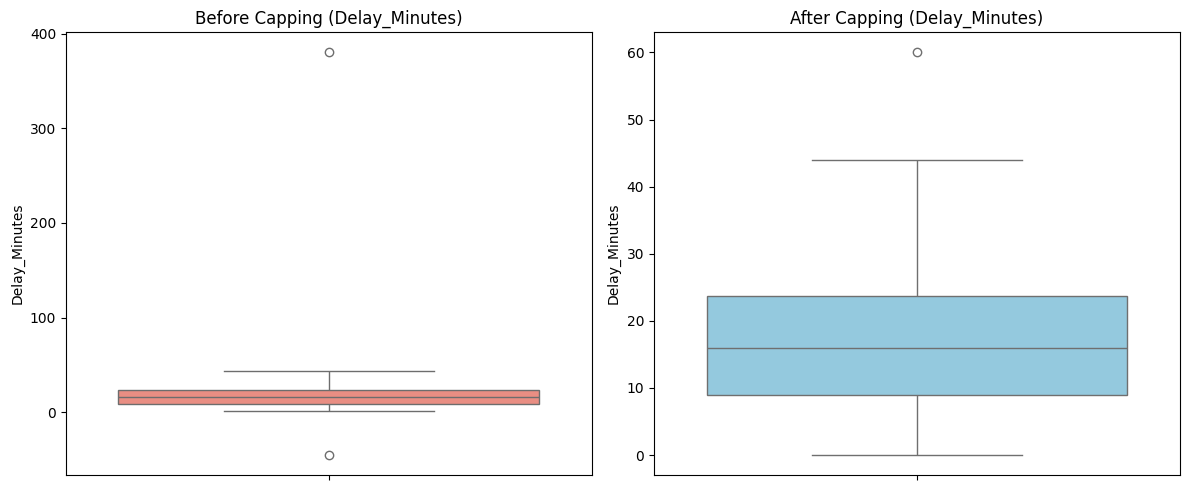

In [22]:
# Define the missing variables
col = "Delay_Minutes"
before = df[col]
df_capped = df.copy()
lower, upper = 0, 60

# Apply capping to the new dataset
df_capped[col] = before.clip(lower, upper)

# Compare descriptive statistics
comparison = pd.DataFrame({
    "Before Capping": before.describe(),
    "After Capping": df_capped[col].describe()
})

print("Descriptive Statistics")
display(comparison.round(2))

# Print maximum values
print("Maximum before:", before.max())
print("Maximum after:", df_capped[col].max())
print("Upper limit:", upper)

# Plot before and after
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
sns.boxplot(y=before, color="salmon")
plt.title("Before Capping (Delay_Minutes)")

plt.subplot(1, 2, 2)
sns.boxplot(y=df_capped[col], color="skyblue")
plt.title("After Capping (Delay_Minutes)")
plt.tight_layout()
plt.show()

Upper limit: 60


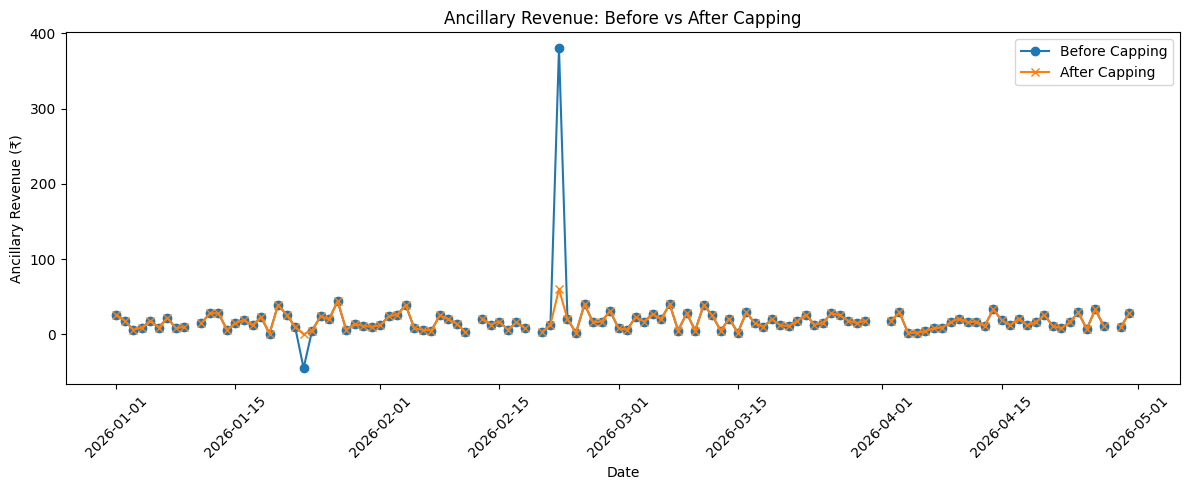

In [23]:
print("Upper limit:", upper)

# Plot before and after
plt.figure(figsize=(12, 5))

plt.plot(raw["Date"], before, label="Before Capping", marker="o")
plt.plot(raw["Date"], df_capped[col], label="After Capping", marker="x")

plt.title("Ancillary Revenue: Before vs After Capping")
plt.xlabel("Date")
plt.ylabel("Ancillary Revenue (₹)")
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()